# Comparison notebook 

In this notebook we will use function from the main notebook and then from this base, realise further analysis and interpretations of the ReMoCo circular task. 

In [10]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")
import numpy as np
import matplotlib.pyplot as plt
from src.circular import full_analysis,read_header, theory_error


res_prof = full_analysis("data/001MoDe_R1.csv", "data/001MoDe_R1.marker.csv", show_plots=False)
res_tub  = full_analysis("data/tub_data.csv", "data/tub_marker.csv", show_plots=False)

data/001MoDe_R1.csv: 5 records
recomputed statistics:
   Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
  unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,
Theory ,  1.00 ,  209.50 ,   47.00 ,    3.88 ,         ,         ,    1.00 ,         ,
Rec001 , -10.84 ,  213.86 ,   91.79 ,    3.90 ,    1.84 ,   14.64 ,    1.95 ,    7.94 ,
Rec002 , -11.97 ,  209.85 ,   34.45 ,    0.74 ,    1.59 ,   38.27 ,    0.73 ,   24.04 ,
Rec003 , -13.26 ,  209.43 ,   42.42 ,    2.81 ,    1.45 ,   31.02 ,    0.90 ,   21.40 ,
Rec004 , -12.83 ,  209.46 ,   37.14 ,    0.13 ,    1.49 ,   35.43 ,    0.79 ,   23.72 ,
Rec005 , -14.74 ,  210.89 ,   43.88 ,    2.84 ,    1.30 ,   30.20 ,    0.93 ,   23.20 ,
data/tub_data.csv: 6 records
recomputed statistics:
   Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
  unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,
Theory ,  1.00 ,  2

In [11]:
sessions = {
    "Prof-(001MoDe_R1)": {"data_file": "data/001MoDe_R1.csv", "stats": res_prof},
    "Tub-(tub_data.csv)":               {"data_file": "data/tub_data.csv",   "stats": res_tub},
}
for record in sessions.values():
    record["header"] = read_header(record["data_file"])

for name, record in sessions.items():
    h = record["header"]
    print(f"{name}: R = {h['taskRadius']} px, T = {h['taskTolerance']} px, {len(record['stats'])} records")

Prof-(001MoDe_R1): R = 209.5 px, T = 47.0 px, 5 records
Tub-(tub_data.csv): R = 268.5 px, T = 47.0 px, 6 records


As the tests differ in geometry due to variations in screen size (i.e., different target radii and tolerances), raw measurements (`Re` and `Te`, expressed in pixels) cannot be directly compared across conditions. Therefore, these variables are normalised relative to their respective task-specific nominal values:

- **`Re / R`**: Normalised radius, where 1 indicates a perfectly matched radius and 0 indicates no radius matching.
- **`Be = Te / T`**: Normalised tolerance, where 1 corresponds to the accuracy required by the task, while values greater than 1 indicate lower accuracy.
- **`Error – theory`**: Deviation from the theoretical error of 3.88%.

Conversely, **`MT/lap`** (s/lap) and **`IPe`** (bit/s) are directly comparable across tests and therefore do not require normalisation.

In [23]:
def normalise(stats, header):
    R, T = header["taskRadius"], header["taskTolerance"]#extracting the task radius and tolerance from the header
    get = lambda k: np.array([r[k] for r in stats]) #extract the values of a given key from the stats records
    return {
        "Re / R":             get("Re") / R,
        "Be (Te / T)":        get("Te") / T,
        "error - theory (%)": get("error") - theory_error(),
        "MT/lap (s)":         get("MT/lap"),
        "IPe (bit/s)":        get("IPe"),
    }

for record in sessions.values():
    record["norm"] = normalise(record["stats"], record["header"]) #setting the normalised values for each record in the sessions dictionary 

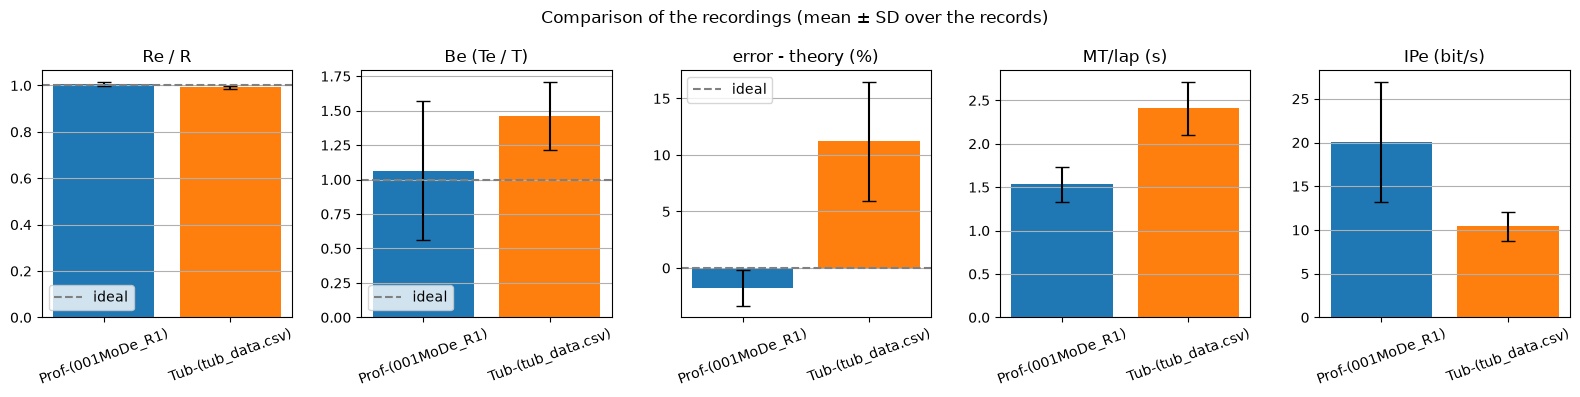

In [26]:
# one small panel per indicator: bar = mean over the records, black line = standard deviation
references = {"Re / R": 1, "Be (Te / T)": 1, "error - theory (%)": 0}  # ideal values (none for MT and IPe)
colors = ["tab:blue", "tab:orange"]

fig, axes = plt.subplots(1, len(indicators), figsize=(3.2 * len(indicators), 4))
for ax, k in zip(axes, indicators):
    means = [s["norm"][k].mean() for s in sessions.values()]
    sds = [s["norm"][k].std(ddof=1) for s in sessions.values()]
    ax.bar(list(sessions.keys()), means, yerr=sds, capsize=5, color=colors[:len(sessions)])
    if k in references:
        ax.axhline(references[k], color="grey", linestyle="--", label="ideal")
        ax.legend()
    ax.set_title(k)
    ax.tick_params(axis="x", labelrotation=20)
    ax.grid(True, axis="y")
plt.suptitle("Comparison of the recordings (mean ± SD over the records)")
plt.tight_layout()
plt.show()

## **Interpretation**
- **Radius**: both participants keep the requested radius (`Re / R` = 1.01 for the reference file, 0.99 for Tub).
- **Precision**: the reference recording is close to the requested precision (mean `Be` = 1.06; records 2-5 below 1),
  whereas Tub is clearly less precise (mean `Be` = 1.46, error 11 points above the theoretical 3.88 %).
- **Speed**: Tub is slower (2.41 s/lap vs 1.54 s/lap), but the task is also harder (index of difficulty 35.9 vs 28.0,
  larger radius with the same tolerance), so part of the gap is expected.
- **Overall performance**: `IPe` is about twice as high in the reference recording (20.1 vs 10.4 bit/s).

- **Limits**: 5-6 records per recording and two different task difficulties, so this comparison is descriptive only. 
- The sensivity of the mouse (DPI),the setup may surely be different as it's not specified, mouse pad, height of the desk, distance subject-screen.